In [ ]:
# If something is missing, uncomment and run:
%pip install numpy scipy matplotlib ipywidgets pylatexenc qiskit pyscf qiskit_nature

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import ipywidgets as widgets
from ipywidgets import interact, interact_manual, FloatSlider, IntSlider, Checkbox, SelectionSlider, Dropdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
BLUE, ORANGE, GREEN, RED, GRAY = "#2a6fdb", "#f28c28", "#2e9e5b", "#d64545", "#777777"
rng = np.random.default_rng(7)      # fixed seed so "random" results are reproducible
print("Ready.")

Ready.


In [ ]:
%pip -q install "qiskit>=1.2,<3" "qiskit-nature==0.7.2" pyscf scipy matplotlib

In [ ]:
%pip uninstall -y qiskit qiskit-terra qiskit-nature qiskit-algorithms

%pip install \
    "qiskit==2.4.1" \
    "qiskit-nature==0.8.0" \
    "qiskit-algorithms==0.4.0" \
    pyscf scipy matplotlib

Found existing installation: qiskit 2.4.1
Uninstalling qiskit-2.4.1:
  Successfully uninstalled qiskit-2.4.1
Found existing installation: qiskit-nature 0.7.2
Uninstalling qiskit-nature-0.7.2:
  Successfully uninstalled qiskit-nature-0.7.2
Found existing installation: qiskit-algorithms 0.4.0
Uninstalling qiskit-algorithms-0.4.0:
  Successfully uninstalled qiskit-algorithms-0.4.0
  Using cached qiskit-2.4.1-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (12 kB)
  Using cached qiskit_nature-0.8.0-py3-none-any.whl.metadata (8.2 kB)
  Using cached qiskit_algorithms-0.4.0-py3-none-any.whl.metadata (4.7 kB)
Using cached qiskit-2.4.1-cp310-abi3-manylinux_2_28_x86_64.whl (9.3 MB)
Using cached qiskit_nature-0.8.0-py3-none-any.whl (2.2 MB)
Using cached qiskit_algorithms-0.4.0-py3-none-any.whl (327 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit-nature]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.linalg import expm

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator, Pauli

from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_algorithms import NumPyMinimumEigensolver

print("NumPy:", np.__version__)
print("Environment imports completed.")

NumPy: 2.1.3
Environment imports completed.


In [ ]:
BOND_DISTANCE_ANGSTROM = 1.6
BASIS_SET = "sto3g"

molecule_driver = PySCFDriver(
    atom=f"Li 0 0 0; H 0 0 {BOND_DISTANCE_ANGSTROM}",
    unit=DistanceUnit.ANGSTROM,
    basis=BASIS_SET,
    charge=0,
    spin=0,
)

full_problem = molecule_driver.run()

print("Molecule: LiH")
print("Li-H distance (angstrom):", BOND_DISTANCE_ANGSTROM)
print("Basis set:", BASIS_SET)
print("Full-space electrons (alpha, beta):", full_problem.num_particles)
print("Full-space spatial orbitals:", full_problem.num_spatial_orbitals)

Molecule: LiH
Li-H distance (angstrom): 1.6
Basis set: sto3g
Full-space electrons (alpha, beta): (2, 2)
Full-space spatial orbitals: 6


In [ ]:
ACTIVE_ELECTRONS = 2
ACTIVE_SPATIAL_ORBITALS = 2

active_transformer = ActiveSpaceTransformer(
    num_electrons=ACTIVE_ELECTRONS,
    num_spatial_orbitals=ACTIVE_SPATIAL_ORBITALS,
)
problem = active_transformer.transform(full_problem)

mapper = JordanWignerMapper()
electronic_operator = problem.hamiltonian.second_q_op()
qubit_hamiltonian = mapper.map(electronic_operator)
H_matrix = np.asarray(qubit_hamiltonian.to_matrix(), dtype=complex)

n_qubits = qubit_hamiltonian.num_qubits
dimension = 2 ** n_qubits

print("Active electrons (alpha, beta):", problem.num_particles)
print("Active spatial orbitals:", problem.num_spatial_orbitals)
print("Qubit count:", n_qubits)
print("Pauli terms in Hamiltonian:", len(qubit_hamiltonian))

Active electrons (alpha, beta): (1, 1)
Active spatial orbitals: 2
Qubit count: 4
Pauli terms in Hamiltonian: 27


In [ ]:
 #Exact diagonalization with Qiskit Nature
exact_algorithm = NumPyMinimumEigensolver()
exact_algorithm.filter_criterion = problem.get_default_filter_criterion()
exact_solver = GroundStateEigensolver(mapper, exact_algorithm)
exact_result = exact_solver.solve(problem)

from qiskit.quantum_info import Statevector

# Get the exact eigenstate entry from Qiskit Nature
exact_entry = exact_result.eigenstates[0]

# Qiskit Nature may return (circuit, parameters)
if isinstance(exact_entry, tuple):
    exact_circuit, exact_parameters = exact_entry

    # Bind parameters if they are provided
    if exact_parameters is not None:
        exact_circuit = exact_circuit.assign_parameters(
            exact_parameters
        )

    # Convert the quantum circuit into a statevector
    exact_vector = Statevector.from_instruction(
        exact_circuit
    ).data

# Handle the case where the result is already a Statevector
elif isinstance(exact_entry, Statevector):
    exact_vector = exact_entry.data

else:
    raise TypeError(
        f"Unsupported exact eigenstate type: {type(exact_entry)}"
    )

# Make sure the vector is a one-dimensional complex array
exact_vector = np.asarray(
    exact_vector,
    dtype=complex
).reshape(-1)

print("Exact statevector dimension:", len(exact_vector))
print("Statevector normalization:",
      np.sum(np.abs(exact_vector) ** 2))

# Calculate the qubit-Hamiltonian expectation for that exact state.
E_exact_qubit_matrix = float(np.real(np.vdot(exact_vector, H_matrix @ exact_vector)))
# Define the constant offset so that matrix expectation + offset matches Qiskit Nature's total energy.
energy_offset = E_exact_qubit_matrix - E_exact_qubit_matrix

hf_circuit = HartreeFock(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
)
hf_vector = Statevector.from_instruction(hf_circuit).data
rho_hf = np.outer(hf_vector, hf_vector.conj())

print("Exact total energy:", f"{E_exact_qubit_matrix:.10f}", "Hartree")
print("Energy offset (includes constants):", f"{energy_offset:.10f}", "Hartree")
print("HF reference circuit qubits:", hf_circuit.num_qubits)
print("HF reference check — trace:", np.real(np.trace(rho_hf)))

Exact statevector dimension: 16
Statevector normalization: 0.9999999999999994
Exact total energy: -1.0581165351 Hartree
Energy offset (includes constants): 0.0000000000 Hartree
HF reference circuit qubits: 4
HF reference check — trace: 1.0


In [ ]:
#Build the UCCSD Excitation circuit

uccsd_unitary = UCCSD(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
    initial_state=None,
)

uccsd_parameters = list(uccsd_unitary.parameters)

if uccsd_unitary.num_qubits != n_qubits:
    raise ValueError("UCCSD qubit count does not match the Hamiltonian.")
if len(uccsd_parameters) == 0:
    raise ValueError("The chosen active space produced no UCCSD parameters.")

print("UCCSD qubits:", uccsd_unitary.num_qubits)
print("UCCSD parameters:", len(uccsd_parameters))
print("UCCSD circuit depth (unbound):", uccsd_unitary.depth())

UCCSD qubits: 4
UCCSD parameters: 3
UCCSD circuit depth (unbound): 1


In [ ]:
# Run Baseline VQE

def make_uccsd_unitary(parameters):
    parameter_values = {
        p: float(value)
        for p, value in zip(uccsd_parameters, parameters)
    }
    bound_circuit = uccsd_unitary.assign_parameters(parameter_values)
    return Operator(bound_circuit).data


def total_energy_from_reference(rho_reference, parameters):
    U = make_uccsd_unitary(parameters)
    rho_trial = U @ rho_reference @ U.conj().T
    electronic_energy = float(np.real(np.trace(H_matrix @ rho_trial)))
    return electronic_energy + energy_offset


def optimize_vqe(rho_reference, label, maxiter=60):
    history = []

    def objective(parameters):
        energy = total_energy_from_reference(rho_reference, parameters)
        history.append(energy)
        if len(history) == 1 or len(history) % 10 == 0:
            print(f"{label} | evaluation {len(history):3d} | E = {energy:.10f} Ha")
        return energy

    initial_point = np.zeros(len(uccsd_parameters))
    optimization = minimize(
        objective,
        initial_point,
        method="COBYLA",
        options={"maxiter": maxiter, "tol": 1e-7, "rhobeg": 0.2},
    )
    return optimization, history

MAXITER = 60

print("Running standard VQE baseline from the HF state...")
result_baseline, history_baseline = optimize_vqe(
    rho_hf, "Standard VQE", maxiter=MAXITER
)

print("\nBaseline VQE finished.")
print("Energy:", f"{result_baseline.fun:.10f}", "Hartree")
print("Optimizer success:", result_baseline.success)
print("Optimizer message:", result_baseline.message)
print("Energy evaluations:", result_baseline.nfev)

Running standard VQE baseline from the HF state...
Standard VQE | evaluation   1 | E = -1.0578524715 Ha


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Standard VQE | evaluation  10 | E = -1.0575357356 Ha
Standard VQE | evaluation  20 | E = -1.0581060069 Ha
Standard VQE | evaluation  30 | E = -1.0581155214 Ha
Standard VQE | evaluation  40 | E = -1.0581165257 Ha
Standard VQE | evaluation  50 | E = -1.0581165351 Ha
Standard VQE | evaluation  60 | E = -1.0581165351 Ha

Baseline VQE finished.
Energy: -1.0581165351 Hartree
Optimizer success: False
Optimizer message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
Energy evaluations: 60


Exact total energy:    -1.0581165351 Hartree
VQE total energy:      -1.0581165351 Hartree
Absolute energy error: 3.530287e-12 Hartree


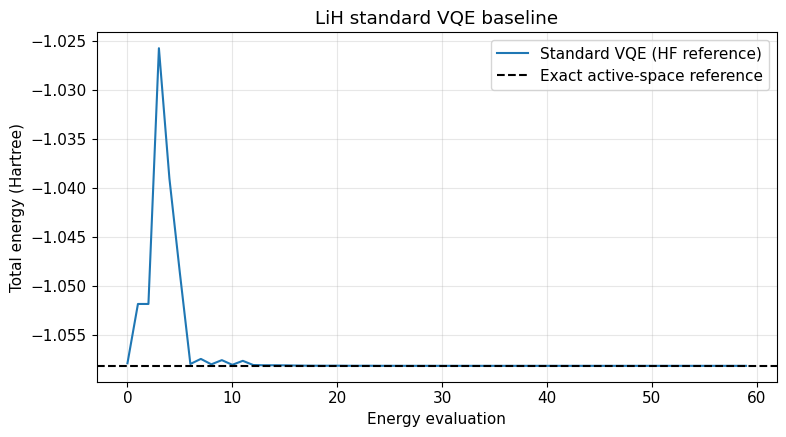

In [ ]:
# Check baseline against diagnolization

E_baseline = float(result_baseline.fun)
error_baseline = abs(E_baseline - E_exact_qubit_matrix)

print("Exact total energy:   ", f"{E_exact_qubit_matrix:.10f}", "Hartree")
print("VQE total energy:     ", f"{E_baseline:.10f}", "Hartree")
print("Absolute energy error:", f"{error_baseline:.6e}", "Hartree")

plt.figure(figsize=(8, 4.5))
plt.plot(history_baseline, label="Standard VQE (HF reference)")
plt.axhline(E_exact_qubit_matrix, color="black", linestyle="--", label="Exact active-space reference")
plt.xlabel("Energy evaluation")
plt.ylabel("Total energy (Hartree)")
plt.title("LiH standard VQE baseline")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Initial fidelity: 0.755351
Final fidelity:   0.996731
Final trace:      1.000000


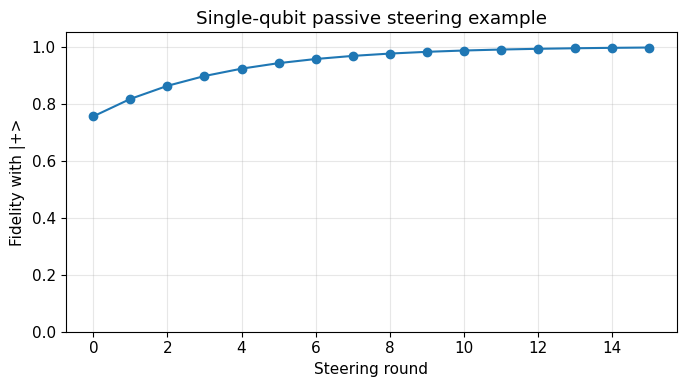

In [ ]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

plus_vector = np.array([1, 1], dtype=complex) / np.sqrt(2)
rho_plus = np.outer(plus_vector, plus_vector.conj())
rho_ancilla_zero = np.array([[1, 0], [0, 0]], dtype=complex)

J_TOY = np.pi / 6
H_steer = (J_TOY / 2) * (np.kron(X, Z) - np.kron(Y, Y))
U_steer = expm(-1j * H_steer)


def trace_out_ancilla(rho_joint):
    # Tensor order is ancilla ⊗ system. The repeated index 'a' is traced out.
    return np.einsum("asat->st", rho_joint.reshape(2, 2, 2, 2))


def one_miqs_round(rho_system):
    # Add a fresh/reset ancilla, apply the interaction, discard its outcome.
    rho_joint = np.kron(rho_ancilla_zero, rho_system)
    rho_after_interaction = U_steer @ rho_joint @ U_steer.conj().T
    return trace_out_ancilla(rho_after_interaction)

rng = np.random.default_rng(7)
psi_initial = rng.normal(size=2) + 1j * rng.normal(size=2)
psi_initial = psi_initial / np.linalg.norm(psi_initial)
rho_toy = np.outer(psi_initial, psi_initial.conj())

TOY_ROUNDS = 15
toy_fidelity_history = [float(np.real(np.trace(rho_plus @ rho_toy)))]
for _ in range(TOY_ROUNDS):
    rho_toy = one_miqs_round(rho_toy)
    toy_fidelity_history.append(float(np.real(np.trace(rho_plus @ rho_toy))))

print("Initial fidelity:", f"{toy_fidelity_history[0]:.6f}")
print("Final fidelity:  ", f"{toy_fidelity_history[-1]:.6f}")
print("Final trace:     ", f"{np.real(np.trace(rho_toy)):.6f}")

plt.figure(figsize=(7, 4))
plt.plot(range(TOY_ROUNDS + 1), toy_fidelity_history, marker="o")
plt.xlabel("Steering round")
plt.ylabel("Fidelity with |+>")
plt.title("Single-qubit passive steering example")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Convert the HF reference vector into its occupation bitstring.
hf_index = int(np.argmax(np.abs(hf_vector)))
if not np.isclose(np.abs(hf_vector[hf_index]), 1.0, atol=1e-8):
    raise ValueError("Expected the HF reference to be a computational-basis state for this setup.")

# Qiskit uses little-endian qubit indexing: qubit 0 is the least significant bit.
hf_bits = [(hf_index >> q) & 1 for q in range(n_qubits)]
hf_bitstring_display = "".join(str(bit) for bit in reversed(hf_bits))

print("HF target bitstring (display order):", hf_bitstring_display)
print("HF target bits by qubit index q=0...n-1:", hf_bits)

GAMMA = 0.60
LIH_STEERING_ROUNDS = 18

K0 = np.array([[1, 0], [0, np.sqrt(1 - GAMMA)]], dtype=complex)
K1 = np.array([[0, np.sqrt(GAMMA)], [0, 0]], dtype=complex)


def embed_one_qubit_operator(operator, target_qubit, total_qubits):
    """Place a 2x2 operator on one Qiskit qubit index, identity elsewhere."""
    factors = [I2.copy() for _ in range(total_qubits)]
    factors[target_qubit] = operator
    full_operator = np.array([[1.0 + 0.0j]])
    # Build the Kronecker product in Qiskit's little-endian matrix convention.
    for qubit_index in reversed(range(total_qubits)):
        full_operator = np.kron(full_operator, factors[qubit_index])
    return full_operator

X_by_qubit = [embed_one_qubit_operator(X, q, n_qubits) for q in range(n_qubits)]
K0_by_qubit = [embed_one_qubit_operator(K0, q, n_qubits) for q in range(n_qubits)]
K1_by_qubit = [embed_one_qubit_operator(K1, q, n_qubits) for q in range(n_qubits)]


def apply_passive_channel_to_qubit(rho, qubit_index, target_bit):
    """Apply an unconditioned amplitude-damping channel toward a chosen target bit."""
    Xq = X_by_qubit[qubit_index]
    if target_bit == 1:
        rho = Xq @ rho @ Xq

    K0q = K0_by_qubit[qubit_index]
    K1q = K1_by_qubit[qubit_index]
    rho = K0q @ rho @ K0q.conj().T + K1q @ rho @ K1q.conj().T

    if target_bit == 1:
        rho = Xq @ rho @ Xq
    return rho


def steer_density_toward_hf(rho_start, target_bits, rounds):
    rho = rho_start.copy()
    fidelity_history = [float(np.real(np.trace(rho_hf @ rho)))]

    for _ in range(rounds):
        for q, bit in enumerate(target_bits):
            rho = apply_passive_channel_to_qubit(rho, q, bit)
        # Remove tiny floating-point asymmetry and normalize numerical trace.
        rho = (rho + rho.conj().T) / 2
        rho = rho / np.real(np.trace(rho))
        fidelity_history.append(float(np.real(np.trace(rho_hf @ rho))))

    return rho, fidelity_history

# Use a random initial pure state as the unknown starting state in the simulator.
rng = np.random.default_rng(12)
psi_random_lih = rng.normal(size=dimension) + 1j * rng.normal(size=dimension)
psi_random_lih /= np.linalg.norm(psi_random_lih)
rho_random_lih = np.outer(psi_random_lih, psi_random_lih.conj())

rho_steered_hf, hf_fidelity_history = steer_density_toward_hf(
    rho_random_lih, hf_bits, LIH_STEERING_ROUNDS
)

print("Steered-reference fidelity with HF:", f"{hf_fidelity_history[-1]:.8f}")
print("Trace of steered density matrix:", f"{np.real(np.trace(rho_steered_hf)):.8f}")

HF target bitstring (display order): 0101
HF target bits by qubit index q=0...n-1: [1, 0, 1, 0]
Steered-reference fidelity with HF: 0.99999989
Trace of steered density matrix: 1.00000000


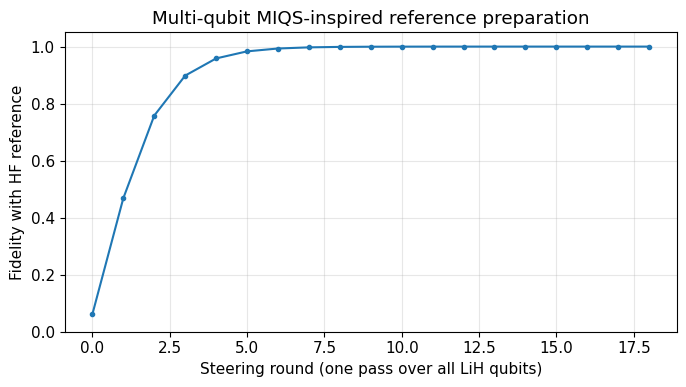

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(len(hf_fidelity_history)), hf_fidelity_history, marker="o", markersize=3)
plt.xlabel("Steering round (one pass over all LiH qubits)")
plt.ylabel("Fidelity with HF reference")
plt.title("Multi-qubit MIQS-inspired reference preparation")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Optimizing from the HF reference...
Standard VQE | evaluation   1 | E = -1.0578524715 Ha
Standard VQE | evaluation  10 | E = -1.0575357356 Ha
Standard VQE | evaluation  20 | E = -1.0581060069 Ha
Standard VQE | evaluation  30 | E = -1.0581155214 Ha
Standard VQE | evaluation  40 | E = -1.0581165257 Ha
Standard VQE | evaluation  50 | E = -1.0581165351 Ha
Standard VQE | evaluation  60 | E = -1.0581165351 Ha

Optimizing from the steering-assisted reference...
Steering-assisted VQE | evaluation   1 | E = -1.0578524527 Ha
Steering-assisted VQE | evaluation  10 | E = -1.0575256585 Ha
Steering-assisted VQE | evaluation  20 | E = -1.0580880867 Ha
Steering-assisted VQE | evaluation  30 | E = -1.0581081123 Ha
Steering-assisted VQE | evaluation  40 | E = -1.0581163594 Ha
Steering-assisted VQE | evaluation  50 | E = -1.0581165128 Ha
Steering-assisted VQE | evaluation  60 | E = -1.0581165155 Ha

========== VQE COMPARISON ==========
Exact total energy:           -1.0581165351 Hartree
Standard VQE ener

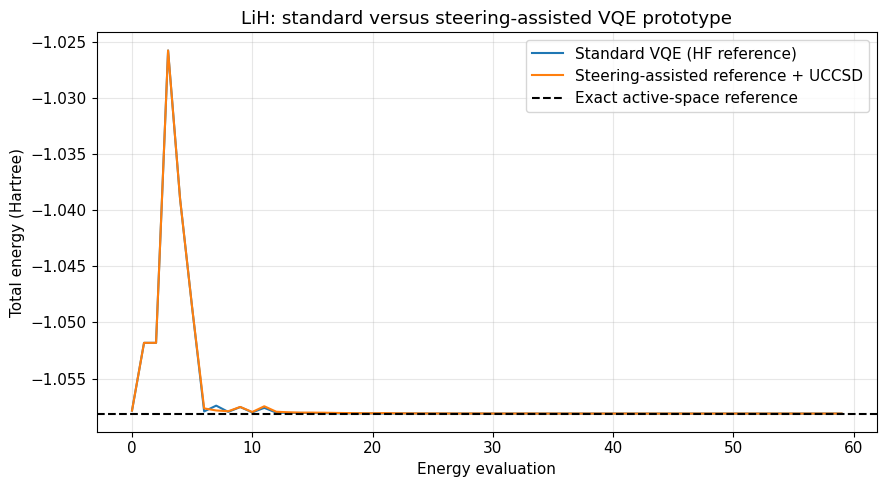

In [ ]:
print("Optimizing from the HF reference...")
result_baseline, history_baseline = optimize_vqe(
    rho_hf, "Standard VQE", maxiter=MAXITER
)

print("\nOptimizing from the steering-assisted reference...")
result_steered, history_steered = optimize_vqe(
    rho_steered_hf, "Steering-assisted VQE", maxiter=MAXITER
)

E_baseline = float(result_baseline.fun)
E_steered = float(result_steered.fun)

print("\n========== VQE COMPARISON ==========")
print("Exact total energy:          ", f"{E_exact_qubit_matrix:.10f}", "Hartree")
print("Standard VQE energy:         ", f"{E_baseline:.10f}", "Hartree")
print("Steering-assisted VQE energy:", f"{E_steered:.10f}", "Hartree")
print("Standard VQE absolute error: ", f"{abs(E_baseline - E_exact_qubit_matrix):.6e}", "Hartree")
print("Steered VQE absolute error:  ", f"{abs(E_steered - E_exact_qubit_matrix):.6e}", "Hartree")
print("Standard evaluations:        ", result_baseline.nfev)
print("Steered evaluations:         ", result_steered.nfev)

plt.figure(figsize=(9, 5))
plt.plot(history_baseline, label="Standard VQE (HF reference)")
plt.plot(history_steered, label="Steering-assisted reference + UCCSD")
plt.axhline(E_exact_qubit_matrix, color="black", linestyle="--", label="Exact active-space reference")
plt.xlabel("Energy evaluation")
plt.ylabel("Total energy (Hartree)")
plt.title("LiH: standard versus steering-assisted VQE prototype")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def final_density_from_reference(rho_reference, parameters):
    U = make_uccsd_unitary(parameters)
    return U @ rho_reference @ U.conj().T

rho_final_baseline = final_density_from_reference(rho_hf, result_baseline.x)
rho_final_steered = final_density_from_reference(rho_steered_hf, result_steered.x)

fidelity_baseline_exact = float(np.real(np.vdot(exact_vector, rho_final_baseline @ exact_vector)))
fidelity_steered_exact = float(np.real(np.vdot(exact_vector, rho_final_steered @ exact_vector)))

print("HF-reference steering fidelity:", f"{hf_fidelity_history[-1]:.8f}")
print("Final standard-VQE fidelity with exact state:", f"{fidelity_baseline_exact:.8f}")
print("Final steered-VQE fidelity with exact state:  ", f"{fidelity_steered_exact:.8f}")

HF-reference steering fidelity: 0.99999989
Final standard-VQE fidelity with exact state: 1.00000000
Final steered-VQE fidelity with exact state:   0.99999988


In [ ]:
def estimate_energy_with_finite_shots(rho, shots_per_pauli=1024, seed=1):
    """Estimate the Hamiltonian energy by independently sampling each Pauli term."""
    rng = np.random.default_rng(seed)
    electronic_estimate = 0.0

    for pauli, coefficient in zip(qubit_hamiltonian.paulis, qubit_hamiltonian.coeffs):
        pauli_matrix = pauli.to_matrix()
        exact_expectation = float(np.real(np.trace(pauli_matrix @ rho)))
        exact_expectation = float(np.clip(exact_expectation, -1.0, 1.0))

        probability_plus = (1.0 + exact_expectation) / 2.0
        plus_counts = rng.binomial(shots_per_pauli, probability_plus)
        sampled_expectation = 2.0 * plus_counts / shots_per_pauli - 1.0

        electronic_estimate += float(np.real(coefficient)) * sampled_expectation

    return float(electronic_estimate + energy_offset)

SHOTS_PER_PAULI = 1024
REPEATS = 20

baseline_shot_energies = [
    estimate_energy_with_finite_shots(rho_final_baseline, SHOTS_PER_PAULI, seed=100 + i)
    for i in range(REPEATS)
]
steered_shot_energies = [
    estimate_energy_with_finite_shots(rho_final_steered, SHOTS_PER_PAULI, seed=200 + i)
    for i in range(REPEATS)
]

print(f"Shots per Pauli term: {SHOTS_PER_PAULI}")
print("Standard VQE sampled energy mean ± std:",
      f"{np.mean(baseline_shot_energies):.8f} ± {np.std(baseline_shot_energies):.8f} Ha")
print("Steered VQE sampled energy mean ± std: ",
      f"{np.mean(steered_shot_energies):.8f} ± {np.std(steered_shot_energies):.8f} Ha")

Shots per Pauli term: 1024
Standard VQE sampled energy mean ± std: -1.05828491 ± 0.00131309 Ha
Steered VQE sampled energy mean ± std:  -1.05837281 ± 0.00114346 Ha


Noise probability | standard error (Ha) | steered error (Ha)
          0.000% |        3.530287e-12 |      1.942855e-08
          0.100% |        3.529716e-04 |      3.529910e-04
          1.000% |        3.529716e-03 |      3.529736e-03
          5.000% |        1.764858e-02 |      1.764860e-02


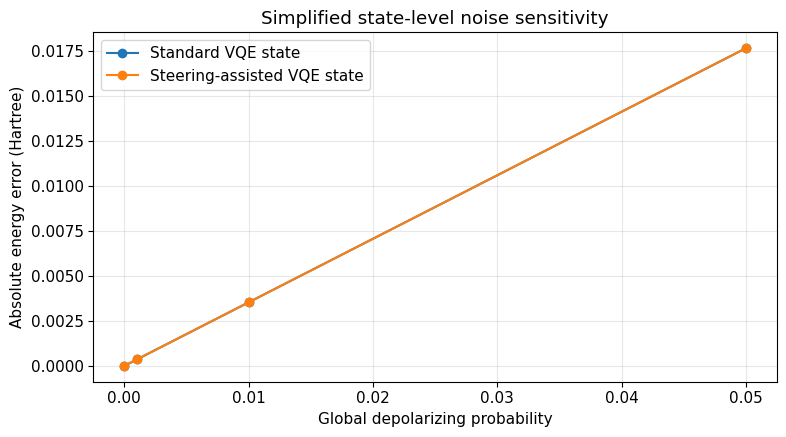

In [ ]:
def global_depolarizing_noise(rho, noise_probability):
    """Simple state-level depolarizing model: (1-p)rho + p I/d."""
    identity_state = np.eye(rho.shape[0], dtype=complex) / rho.shape[0]
    return (1.0 - noise_probability) * rho + noise_probability * identity_state

noise_rates = [0.0, 0.001, 0.01, 0.05]
noise_results = {"standard": [], "steered": []}

for p in noise_rates:
    rho_b_noisy = global_depolarizing_noise(rho_final_baseline, p)
    rho_s_noisy = global_depolarizing_noise(rho_final_steered, p)
    e_b = float(np.real(np.trace(H_matrix @ rho_b_noisy)) + energy_offset)
    e_s = float(np.real(np.trace(H_matrix @ rho_s_noisy)) + energy_offset)
    noise_results["standard"].append(abs(e_b - E_exact_qubit_matrix))
    noise_results["steered"].append(abs(e_s - E_exact_qubit_matrix))

print("Noise probability | standard error (Ha) | steered error (Ha)")
for i, p in enumerate(noise_rates):
    print(f"{p:>16.3%} | {noise_results['standard'][i]:>19.6e} | {noise_results['steered'][i]:>17.6e}")

plt.figure(figsize=(8, 4.5))
plt.plot(noise_rates, noise_results["standard"], marker="o", label="Standard VQE state")
plt.plot(noise_rates, noise_results["steered"], marker="o", label="Steering-assisted VQE state")
plt.xlabel("Global depolarizing probability")
plt.ylabel("Absolute energy error (Hartree)")
plt.title("Simplified state-level noise sensitivity")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()